In [3]:

import numpy as np

In [7]:
def f(x):
    return np.log(x[0]**2 + 1) + x[0]**2 - 2*x[0]*x[1] + 4*x[1]**2 + x[2]**4 - 8*x[2]**3 + 16*x[2]**2

In [8]:
f([0,0,0])

0.0

In [9]:
f([0,0,4])

0.0

In [10]:
f([0,0,2])

16.0

In [11]:
f([-2,-0.5,0])

4.6094379124341005

In [12]:
f([-2,-0.5,4])

4.609437912434089

In [13]:
f([-2,-0.5,2])

20.609437912434103

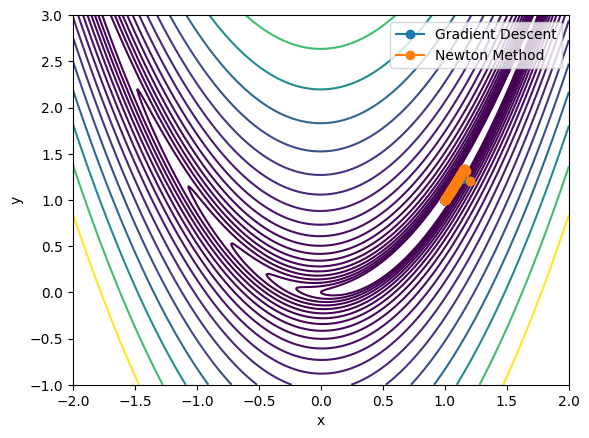

In [14]:
import numpy as np
import matplotlib.pyplot as plt

def rosenbrock(x):
    return 100 * (x[1] - x[0]**2)**2 + (1 - x[0])**2

def rosenbrock_gradient(x):
    dfdx0 = -400 * x[0] * (x[1] - x[0]**2) - 2 * (1 - x[0])
    dfdx1 = 200 * (x[1] - x[0]**2)
    return np.array([dfdx0, dfdx1])

def rosenbrock_hessian(x):
    d2fdx0 = 1200 * x[0]**2 - 400 * x[1] + 2
    d2fdx1 = -400 * x[0]
    return np.array([[d2fdx0, -400], [-400, 200]])

def backtracking_line_search(f, df, x, p, rho=0.9, c=0.6):
    alpha = 1.0
    while f(x + alpha * p) > f(x) + c * alpha * np.dot(df(x), p):
        alpha *= rho
    return alpha

def gradient_descent(x0, max_iter=1000, tol=1e-6):
    x = x0
    path = [x]
    for _ in range(max_iter):
        gradient = rosenbrock_gradient(x)
        if np.linalg.norm(gradient) < tol:
            break
        direction = -gradient
        alpha = backtracking_line_search(rosenbrock, rosenbrock_gradient, x, direction)
        x = x + alpha * direction
        path.append(x)
    return np.array(path)

def newton_method(x0, max_iter=1000, tol=1e-6):
    x = x0
    path = [x]
    for _ in range(max_iter):
        gradient = rosenbrock_gradient(x)
        hessian_inv = np.linalg.inv(rosenbrock_hessian(x))
        if np.linalg.norm(gradient) < tol:
            break
        direction = -np.dot(hessian_inv, gradient)
        alpha = backtracking_line_search(rosenbrock, rosenbrock_gradient, x, direction)
        x = x + alpha * direction
        path.append(x)
    return np.array(path)

# Plotting the contour of the Rosenbrock function
x_range = np.linspace(-2, 2, 400)
y_range = np.linspace(-1, 3, 400)
X, Y = np.meshgrid(x_range, y_range)
Z = rosenbrock(np.array([X, Y]))

plt.contour(X, Y, Z, levels=np.logspace(0, 3, 20), cmap='viridis')
plt.xlabel('x')
plt.ylabel('y')

# Run and plot gradient descent
path_gd = gradient_descent(np.array([1.2, 1.2]))
plt.plot(path_gd[:, 0], path_gd[:, 1], marker='o', label='Gradient Descent')

# Run and plot Newton method
path_newton = newton_method(np.array([1.2, 1.2]))
plt.plot(path_newton[:, 0], path_newton[:, 1], marker='o', label='Newton Method')

plt.legend()
plt.show()


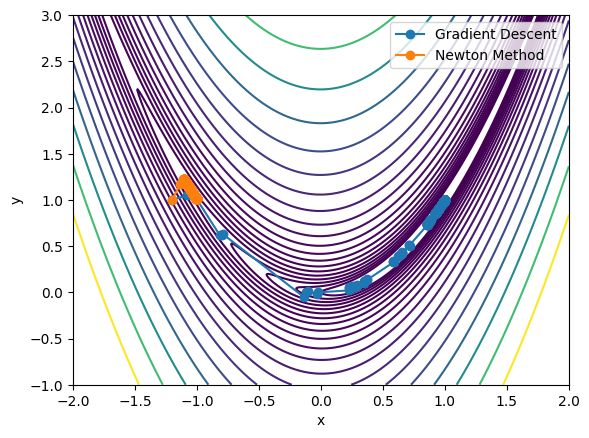

In [15]:
plt.contour(X, Y, Z, levels=np.logspace(0, 3, 20), cmap='viridis')
plt.xlabel('x')
plt.ylabel('y')

# Run and plot gradient descent
path_gd = gradient_descent(np.array([-1.2, 1]))
plt.plot(path_gd[:, 0], path_gd[:, 1], marker='o', label='Gradient Descent')

# Run and plot Newton method
path_newton = newton_method(np.array([-1.2, 1]))
plt.plot(path_newton[:, 0], path_newton[:, 1], marker='o', label='Newton Method')

plt.legend()
plt.show()